In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
data=pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")
data

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes


In [3]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [4]:
data.describe()


,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [5]:
data.duplicated()

0       False
1       False
2       False
3       False
4       False
        ...  
7038    False
7039    False
7040    False
7041    False
7042    False
Length: 7043, dtype: bool

In [6]:
# NOTE: dropna() returns a new object and does not modify data in place.
# Since there are no true NaNs at this point (blanks are literal spaces, handled below),
# this line is kept for the record but has no effect until TotalCharges is cleaned.
data.dropna()


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes


In [7]:
data['Churn'].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [8]:
data['Churn'].value_counts(normalize=True)*100

Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64

In [9]:
data.isna().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [10]:
data.duplicated().sum()

np.int64(0)

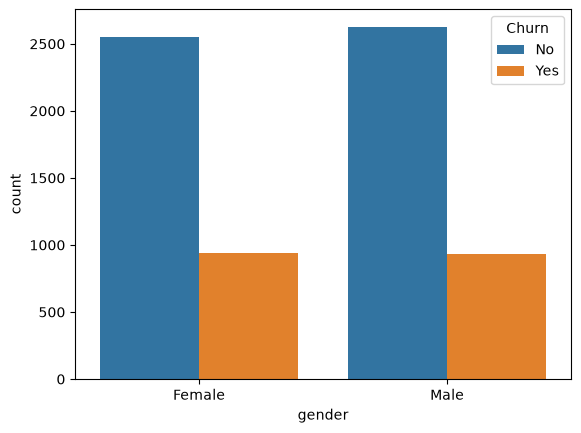

In [11]:
gender_churn=sns.countplot(x='gender',hue='Churn',data=data)
plt.show()

In [12]:
data['SeniorCitizen'].value_counts()

SeniorCitizen
0    5901
1    1142
Name: count, dtype: int64

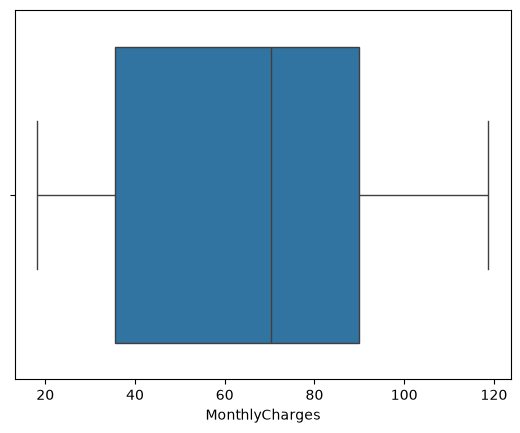

In [13]:
out_mothlycharges=sns.boxplot(x='MonthlyCharges',data=data)
plt.show()

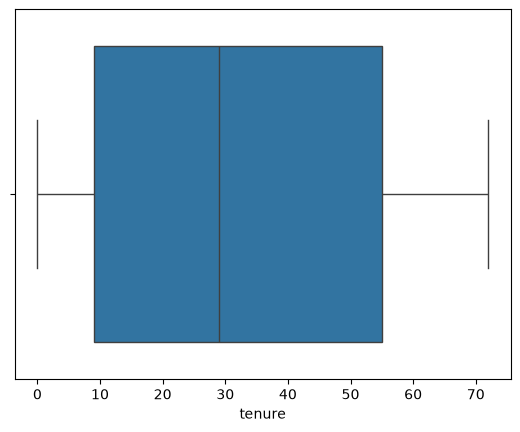

In [14]:
out_tenure=sns.boxplot(x='tenure',data=data)
plt.show()

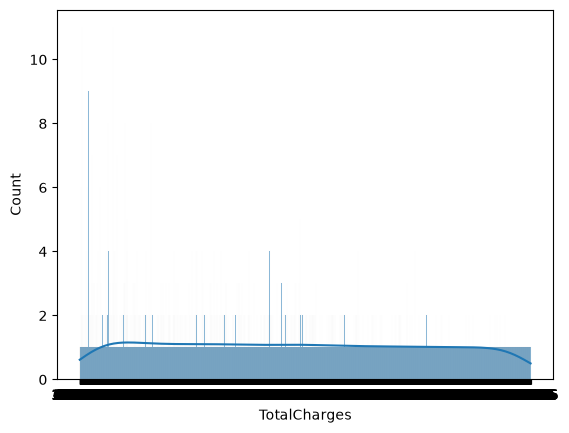

<Axes: xlabel='TotalCharges', ylabel='Count'>

In [15]:
out_=sns.histplot(x='TotalCharges',data=data,kde=True)
plt.show()
out_

In [16]:
data.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [17]:
data['TotalCharges']=data['TotalCharges'].replace(' ',np.nan)

In [18]:
data[data['TotalCharges'].isnull()]

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,NaN,No
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,NaN,No
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,...,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,NaN,No
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,NaN,No
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,NaN,No
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,NaN,No
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,NaN,No
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,NaN,No
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,NaN,No
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,...,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,NaN,No


In [19]:
data['TotalCharges']=data['TotalCharges'].astype(float)

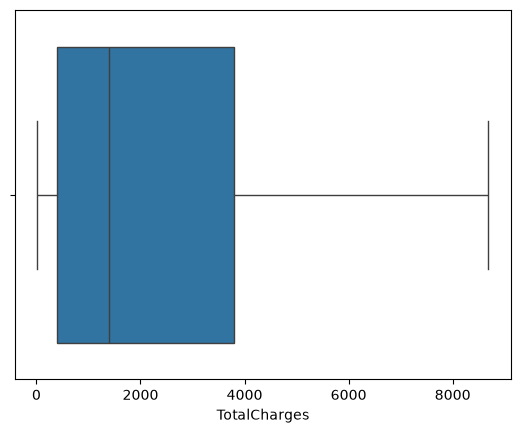

In [20]:
out_totalcharges=sns.boxplot(x='TotalCharges',data=data)

In [21]:
data.columns


Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='str')

<Axes: xlabel='Contract', ylabel='count'>

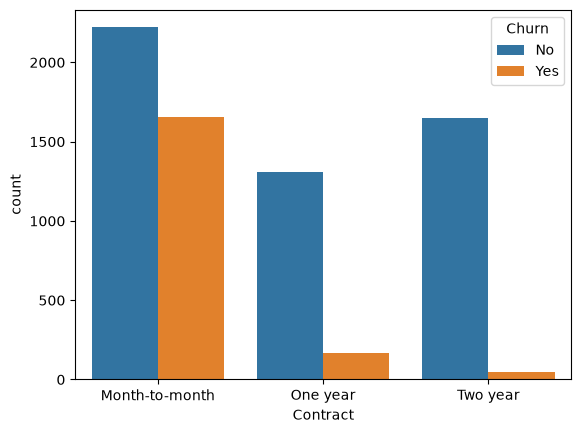

In [22]:
sns.countplot(x='Contract',hue='Churn',data=data)

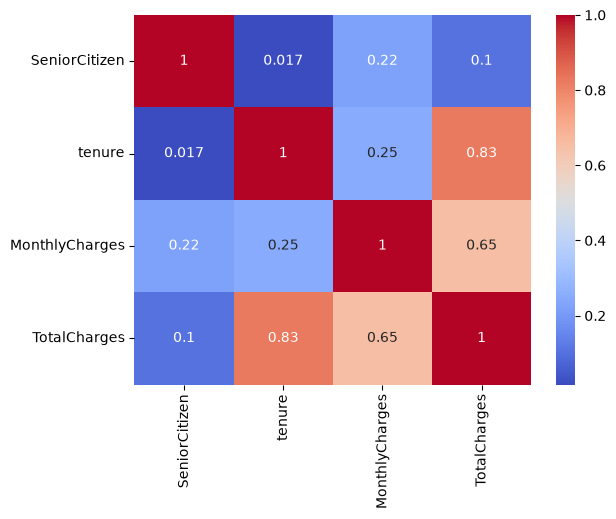

In [23]:
numeric = data.select_dtypes(include='number')

corr = numeric.corr()

sns.heatmap(corr, annot=True, cmap='coolwarm')
plt.show()

In [24]:
data

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.50,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.90,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.60,Yes


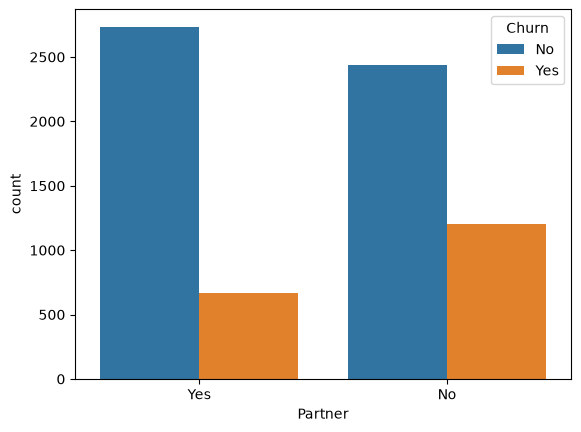

In [25]:
partner_churn=sns.countplot(x='Partner',hue='Churn', data=data)
plt.show()

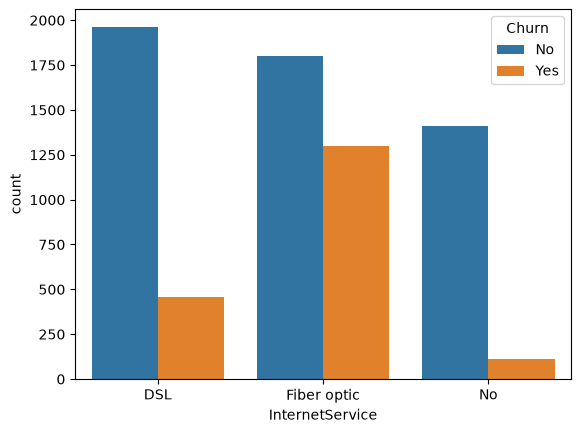

In [26]:
partner_churn=sns.countplot(x='InternetService',hue='Churn', data=data)
plt.show()

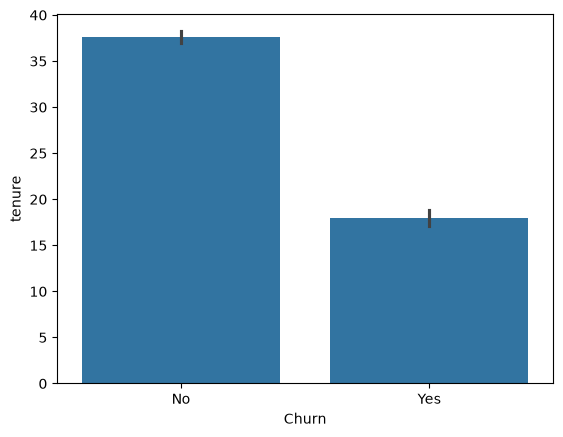

In [27]:
partner_churn=sns.barplot(x='Churn',y='tenure', data=data)
plt.show()

<Axes: xlabel='tenure', ylabel='Churn'>

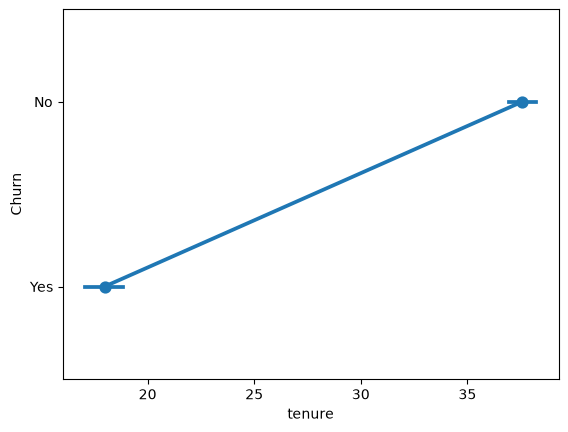

In [28]:
sns.pointplot(x='tenure',y='Churn',data=data)

<Axes: xlabel='Churn', ylabel='tenure'>

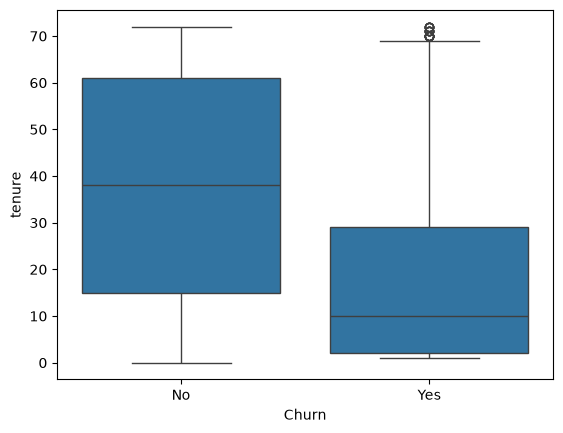

In [29]:
sns.boxplot(x='Churn', y='tenure', data=data)

<Axes: xlabel='Contract', ylabel='tenure'>

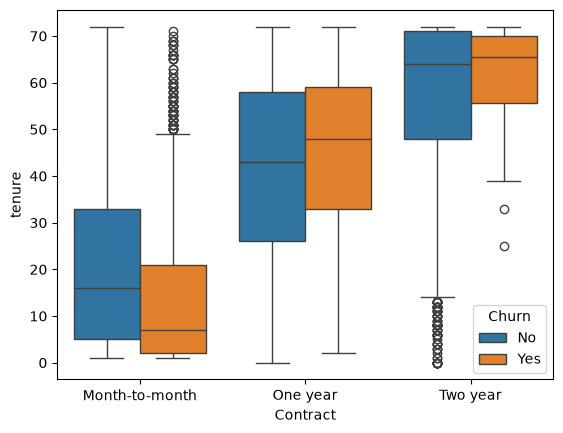

In [30]:
sns.boxplot(x='Contract', y='tenure', hue='Churn', data=data)

<Axes: xlabel='Churn', ylabel='MonthlyCharges'>

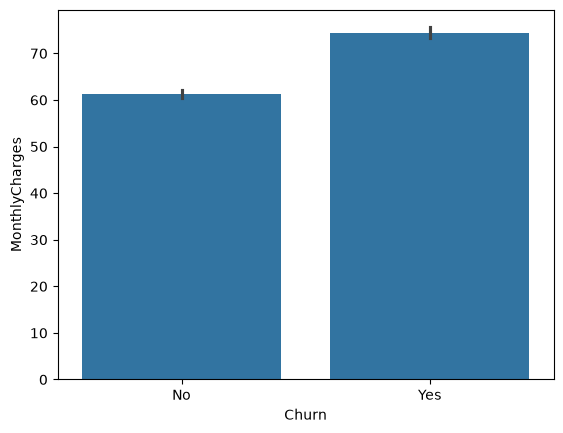

In [31]:
sns.barplot(x='Churn',y='MonthlyCharges',data=data)

In [32]:
data.groupby(['Contract','Churn'])['MonthlyCharges'].mean()

Contract        Churn
Month-to-month  No       61.462635
                Yes      73.019396
One year        No       62.508148
                Yes      85.050904
Two year        No       60.012477
                Yes      86.777083
Name: MonthlyCharges, dtype: float64

In [33]:
totalrevenue=data['MonthlyCharges'].sum()
print(totalrevenue)
churnrevenue=data[data['Churn']=='Yes']['MonthlyCharges'].sum()
print(churnrevenue)

456116.6
139130.85


In [34]:
loss=totalrevenue-churnrevenue
loss

np.float64(316985.75)

In [35]:
data[data['Churn']=='Yes'].groupby('Contract')['MonthlyCharges'].sum()



Contract
Month-to-month    120847.10
One year           14118.45
Two year            4165.30
Name: MonthlyCharges, dtype: float64

In [36]:
data[data['Churn']=='Yes']['MonthlyCharges'].sum()



np.float64(139130.85)

In [37]:
data[data['Churn']=='Yes'].groupby('InternetService')['MonthlyCharges'].sum()

InternetService
DSL             22529.20
Fiber optic    114300.05
No               2301.60
Name: MonthlyCharges, dtype: float64

In [38]:
data[data['Churn']=='Yes'].groupby('InternetService')['MonthlyCharges'].sum()

InternetService
DSL             22529.20
Fiber optic    114300.05
No               2301.60
Name: MonthlyCharges, dtype: float64

In [39]:
data[data['Churn']=='Yes'].groupby('InternetService')['MonthlyCharges'].agg(['count','mean','sum'])

,count,mean,sum
InternetService,,,
DSL,459,49.083224,22529.20
Fiber optic,1297,88.126484,114300.05
No,113,20.368142,2301.60


In [40]:
data.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='str')

<Axes: xlabel='OnlineSecurity', ylabel='count'>

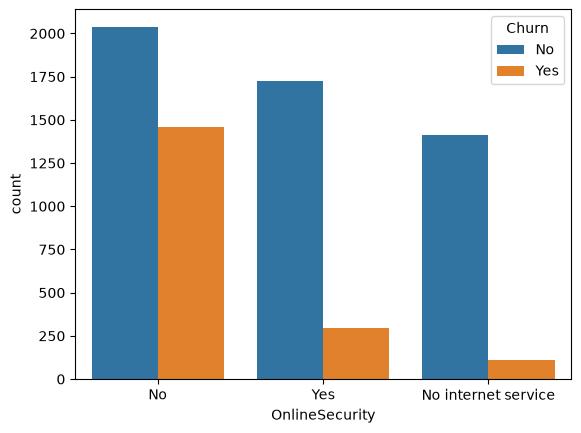

In [41]:
sns.countplot(x='OnlineSecurity',hue='Churn',data=data)

In [42]:
data[data['Churn']=='Yes'].groupby(['OnlineSecurity','InternetService'])['MonthlyCharges'].sum()

OnlineSecurity       InternetService
No                   DSL                16112.20
                     Fiber optic        96650.55
No internet service  No                  2301.60
Yes                  DSL                 6417.00
                     Fiber optic        17649.50
Name: MonthlyCharges, dtype: float64

In [43]:
# Median tenure: churned vs retained customers
tenure_by_churn = data.groupby('Churn')['tenure'].median()
print(tenure_by_churn)


Churn
No     38.0
Yes    10.0
Name: tenure, dtype: float64


In [44]:
# % difference in average MonthlyCharges: churned vs retained, by contract type
avg_charges = data.groupby(['Contract', 'Churn'])['MonthlyCharges'].mean().unstack()
avg_charges['pct_higher_if_churned'] = ((avg_charges['Yes'] - avg_charges['No']) / avg_charges['No']) * 100
print(avg_charges)


Churn                  No        Yes  pct_higher_if_churned
Contract                                                   
Month-to-month  61.462635  73.019396              18.802905
One year        62.508148  85.050904              36.063706
Two year        60.012477  86.777083              44.598402


In [45]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [46]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder,StandardScaler
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score,classification_report

In [47]:
data

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.50,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.90,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.60,Yes


In [48]:
cat_cols = [
    "gender", "Partner", "Dependents", "PhoneService", "MultipleLines",
    "InternetService", "OnlineSecurity", "OnlineBackup", "DeviceProtection",
    "TechSupport", "StreamingTV", "StreamingMovies", "Contract",
    "PaperlessBilling", "PaymentMethod",
]

In [49]:
ct = ColumnTransformer(
    transformers=[
        ("ohe", OneHotEncoder(handle_unknown="ignore", drop="first"), cat_cols),
        ("scale", StandardScaler(), ["tenure", "MonthlyCharges", "TotalCharges"]),
    ],
    remainder="passthrough",  
    sparse_threshold=0,
)

In [50]:
data['TotalCharges'].dtype
data['TotalCharges']=data['TotalCharges'].fillna(0)
data.isna().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [51]:
y = data["Churn"].map({"Yes": 1, "No": 0})
X = data.drop(columns=["Churn", "customerID"])

In [52]:
print(X)

      gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0     Female              0     Yes         No       1           No   
1       Male              0      No         No      34          Yes   
2       Male              0      No         No       2          Yes   
3       Male              0      No         No      45           No   
4     Female              0      No         No       2          Yes   
...      ...            ...     ...        ...     ...          ...   
7038    Male              0     Yes        Yes      24          Yes   
7039  Female              0     Yes        Yes      72          Yes   
7040  Female              0     Yes        Yes      11           No   
7041    Male              1     Yes         No       4          Yes   
7042    Male              0      No         No      66          Yes   

         MultipleLines InternetService OnlineSecurity OnlineBackup  \
0     No phone service             DSL             No          Yes   
1      

In [53]:
y

0       0
1       0
2       1
3       0
4       1
       ..
7038    0
7039    0
7040    0
7041    1
7042    0
Name: Churn, Length: 7043, dtype: int64

In [54]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

In [55]:
X_train = ct.fit_transform(X_train)
X_test = ct.transform(X_test)

In [56]:
print(X_train)

[[ 0.          1.          1.         ... -0.37146069  0.65293105
   0.        ]
 [ 0.          0.          0.         ... -0.62503158 -0.91839261
   0.        ]
 [ 1.          0.          1.         ... -1.44706533 -0.46103082
   0.        ]
 ...
 [ 0.          1.          0.         ...  1.47148594  2.37012207
   0.        ]
 [ 0.          1.          0.         ... -1.47358254 -0.79182543
   0.        ]
 [ 1.          0.          0.         ... -1.46529591 -0.95528616
   0.        ]]


In [57]:
X_test.shape


(1761, 30)

In [58]:
model = LogisticRegression(max_iter=5000, class_weight="balanced")
model.fit(X_train, y_train)
print(classification_report(y_test, model.predict(X_test)))

              precision    recall  f1-score   support

           0       0.91      0.73      0.81      1294
           1       0.52      0.80      0.63       467

    accuracy                           0.75      1761
   macro avg       0.71      0.76      0.72      1761
weighted avg       0.81      0.75      0.76      1761



In [59]:
print(accuracy_score(y_test, model.predict(X_test)))

0.7501419647927314


In [60]:
rfmodel = RandomForestClassifier(
    n_estimators=300,
    max_depth=10,
    min_samples_leaf=5,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1,
)
rfmodel.fit(X_train, y_train)

rf_pred = rfmodel.predict(X_test)
print("Accuracy:", accuracy_score(y_test, rf_pred))
print(classification_report(y_test, rf_pred))

Accuracy: 0.7649063032367973
              precision    recall  f1-score   support

           0       0.91      0.75      0.82      1294
           1       0.54      0.80      0.64       467

    accuracy                           0.76      1761
   macro avg       0.73      0.78      0.73      1761
weighted avg       0.81      0.76      0.78      1761



In [61]:
xgb_model = XGBClassifier(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=4,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1,
)
xgb_model.fit(X_train, y_train)

xgb_pred = xgb_model.predict(X_test)
print("Accuracy:", accuracy_score(y_test, xgb_pred))
print(classification_report(y_test, xgb_pred))

Accuracy: 0.797274275979557
              precision    recall  f1-score   support

           0       0.83      0.90      0.87      1294
           1       0.65      0.50      0.57       467

    accuracy                           0.80      1761
   macro avg       0.74      0.70      0.72      1761
weighted avg       0.79      0.80      0.79      1761



## Model Evaluation: ROC-AUC and Cross-Validation
Accuracy alone is misleading on imbalanced data (~27% churn). Below: ROC curves / AUC on the hold-out test set, then 5-fold stratified cross-validation on the training data for a more stable estimate.

In [62]:
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.base import clone

### 1. ROC curve and AUC (hold-out test set)

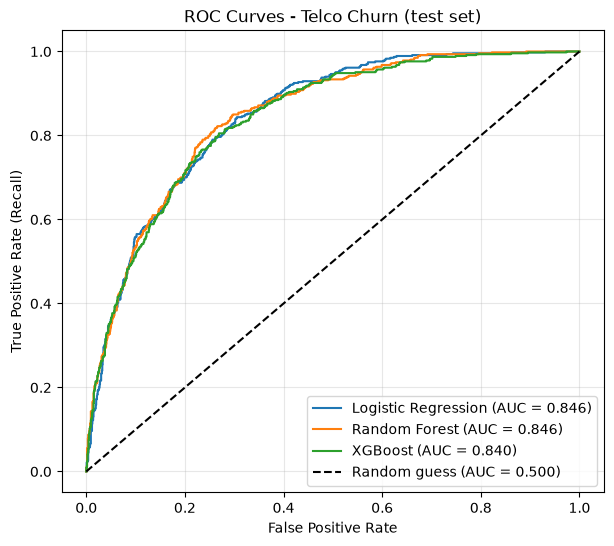

,Model,Test ROC-AUC
0,Logistic Regression,0.8462
1,Random Forest,0.8460
2,XGBoost,0.8404


In [63]:
models = {
    "Logistic Regression": model,
    "Random Forest": rfmodel,
    "XGBoost": xgb_model,
}

plt.figure(figsize=(7, 6))
roc_rows = []
for name, m in models.items():
    proba = m.predict_proba(X_test)[:, 1]
    auc = roc_auc_score(y_test, proba)
    fpr, tpr, _ = roc_curve(y_test, proba)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc:.3f})")
    roc_rows.append({"Model": name, "Test ROC-AUC": round(auc, 4)})

plt.plot([0, 1], [0, 1], "k--", label="Random guess (AUC = 0.500)")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC Curves - Telco Churn (test set)")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.show()

pd.DataFrame(roc_rows).sort_values("Test ROC-AUC", ascending=False).reset_index(drop=True)

### 2. 5-fold stratified cross-validation
The preprocessing (`ColumnTransformer`) is placed **inside** a `Pipeline`, so scaling and encoding are re-fit on each training fold only. This avoids data leakage. CV runs on the raw training split only; the test set stays untouched.

In [64]:
# Re-create the same raw train split used earlier (same random_state + stratify -> identical rows)
X_train_raw, X_test_raw, y_train_raw, y_test_raw = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc",
}

cv_rows = []
cv_raw = {}
for name, m in models.items():
    pipe = Pipeline([("prep", clone(ct)), ("clf", clone(m))])
    res = cross_validate(pipe, X_train_raw, y_train_raw, cv=cv, scoring=scoring, n_jobs=1)
    cv_raw[name] = res["test_roc_auc"]
    row = {"Model": name}
    for metric in scoring:
        scores = res[f"test_{metric}"]
        row[metric] = f"{scores.mean():.3f} ± {scores.std():.3f}"
    cv_rows.append(row)

cv_report = pd.DataFrame(cv_rows).set_index("Model")
print("5-fold stratified CV (mean ± std), churn = positive class")
cv_report

5-fold stratified CV (mean ± std), churn = positive class


,accuracy,precision,recall,f1,roc_auc
Model,,,,,
Logistic Regression,0.748 ± 0.007,0.516 ± 0.010,0.796 ± 0.026,0.626 ± 0.011,0.844 ± 0.015
Random Forest,0.761 ± 0.010,0.535 ± 0.015,0.770 ± 0.019,0.631 ± 0.012,0.845 ± 0.014
XGBoost,0.798 ± 0.008,0.653 ± 0.018,0.511 ± 0.022,0.573 ± 0.019,0.842 ± 0.014


### 3. CV ROC-AUC per fold

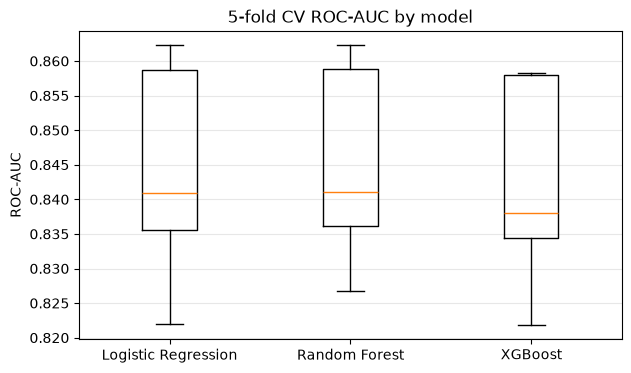

In [65]:
plt.figure(figsize=(7, 4))
plt.boxplot(list(cv_raw.values()))
plt.xticks(range(1, len(cv_raw) + 1), list(cv_raw.keys()))
plt.ylabel("ROC-AUC")
plt.title("5-fold CV ROC-AUC by model")
plt.grid(axis="y", alpha=0.3)
plt.show()

### Summary: test vs cross-validated ROC-AUC

In [66]:
summary = pd.DataFrame(roc_rows).set_index("Model")
summary["CV ROC-AUC (mean)"] = {k: round(v.mean(), 4) for k, v in cv_raw.items()}
summary["CV ROC-AUC (std)"] = {k: round(v.std(), 4) for k, v in cv_raw.items()}
summary.sort_values("CV ROC-AUC (mean)", ascending=False)

,Test ROC-AUC,CV ROC-AUC (mean),CV ROC-AUC (std)
Model,,,
Random Forest,0.8460,0.8450,0.0136
Logistic Regression,0.8462,0.8439,0.0149
XGBoost,0.8404,0.8421,0.0141


In [68]:
print(accuracy_score(y_train,xgb_model.predict(X_train)))

0.8445664521014767


In [67]:
pip install streamlit


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.2.1
[notice] To update, run: C:\Users\andar\AppData\Local\Programs\Python\Python314\python.exe -m pip install --upgrade pip


In [69]:
import pickle
import streamlit
from sklearn.pipeline import Pipeline
from sklearn.base import clone

final_pipe = Pipeline([
    ("prep", clone(ct)),
    ("clf", clone(xgb_model)),
])
final_pipe.fit(X_train_raw, y_train_raw)      # raw (untransformed) training data

print(accuracy_score(y_test_raw, final_pipe.predict(X_test_raw)))  # should be ~0.797

with open("churn_model.pkl", "wb") as f:
    pickle.dump(final_pipe, f)

0.797274275979557


In [70]:
data.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='str')

In [71]:
   import sys, numpy, sklearn, xgboost
   print(sys.executable)
   print(numpy.__version__, sklearn.__version__, xgboost.__version__)


C:\Users\andar\AppData\Local\Programs\Python\Python314\python.exe
2.5.0 1.9.0 3.4.1


In [73]:
data.iloc[7038]

customerID            6840-RESVB
gender                      Male
SeniorCitizen                  0
Partner                      Yes
Dependents                   Yes
tenure                        24
PhoneService                 Yes
MultipleLines                Yes
InternetService              DSL
OnlineSecurity               Yes
OnlineBackup                  No
DeviceProtection             Yes
TechSupport                  Yes
StreamingTV                  Yes
StreamingMovies              Yes
Contract                One year
PaperlessBilling             Yes
PaymentMethod       Mailed check
MonthlyCharges              84.8
TotalCharges              1990.5
Churn                         No
Name: 7038, dtype: object